# CXC 102

In [66]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import keras
import tensorflow as tf 
import matplotlib.pyplot as plt
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils import (
    generate_confusion, 
    generate_roc_curve, 
    plot_train_accuracy, 
    plot_train_loss, 
    get_dataset_distribution
)


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### load Dataset

In [53]:
load_dotenv()


dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (384, 384)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


## Data Dristribution Table

In [67]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [68]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [69]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


## Data Augmentation

In [70]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])

2026-05-11 11:30:08.464599: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


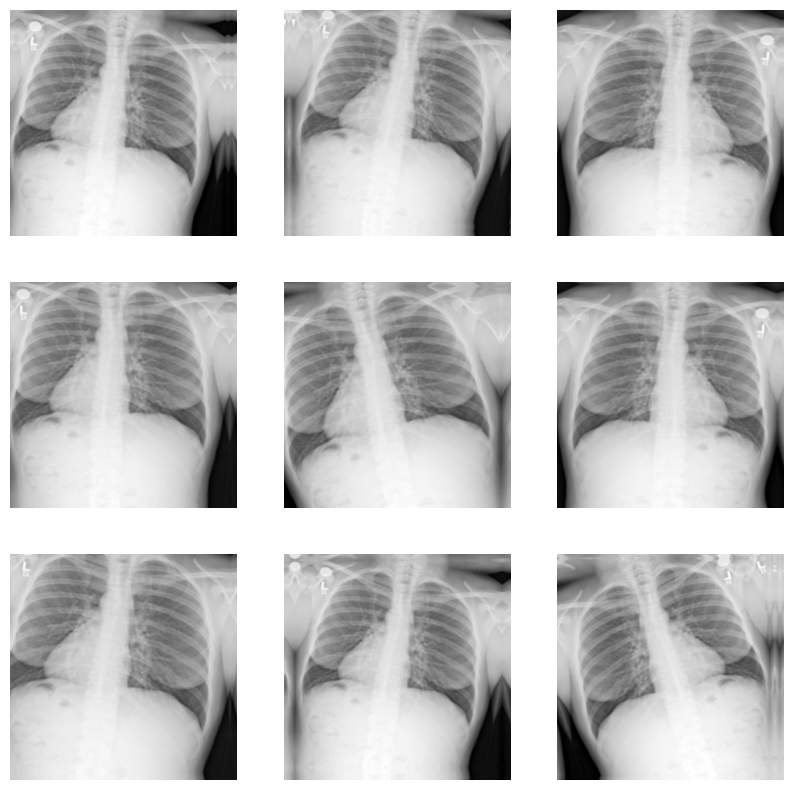

In [72]:
for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [34]:
model = models.Sequential([

    data_augmentation,
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(384, 384, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

In [44]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 334s 534ms/step - accuracy: 0.7217 - loss: 5.4866 - val_accuracy: 0.8292 - val_loss: 4.4162
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 441s 730ms/step - accuracy: 0.7182 - loss: 5.8361 - val_accuracy: 0.8357 - val_loss: 5.7119
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 523s 866ms/step - accuracy: 0.7312 - loss: 4.9108 - val_accuracy: 0.8515 - val_loss: 3.7147
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 528s 873ms/step - accuracy: 0.7306 - loss: 3.2941 - val_accuracy: 0.8502 - val_loss: 2.8927
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 453s 750ms/step - accuracy: 0.7208 - loss: 2.8495 - val_accuracy: 0.8476 - val_loss: 2.3509
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 362s 599ms/step - accuracy: 0.7292 - loss: 1.8771 - val_accuracy: 0.8594 - val_loss: 2.5218
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 602s 997ms/step - accuracy: 0.7470 - loss: 1.4097 - val_accuracy: 0.8436 - val_loss: 2.4939
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 433s 715ms/step - accuracy: 0.7624 -

### Training Data visualisation

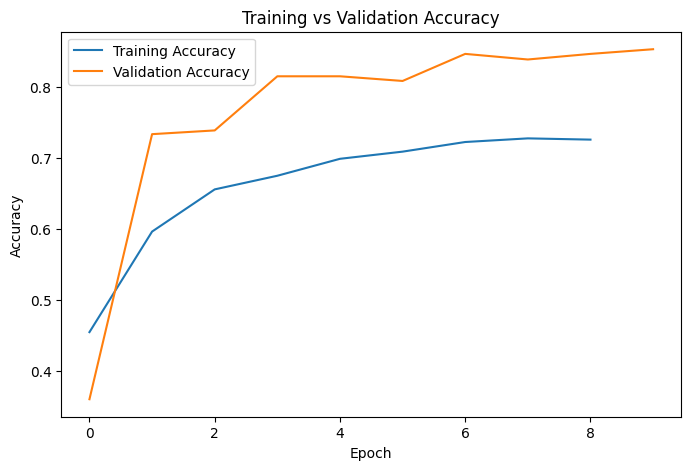

In [36]:
plot_train_accuracy(history)

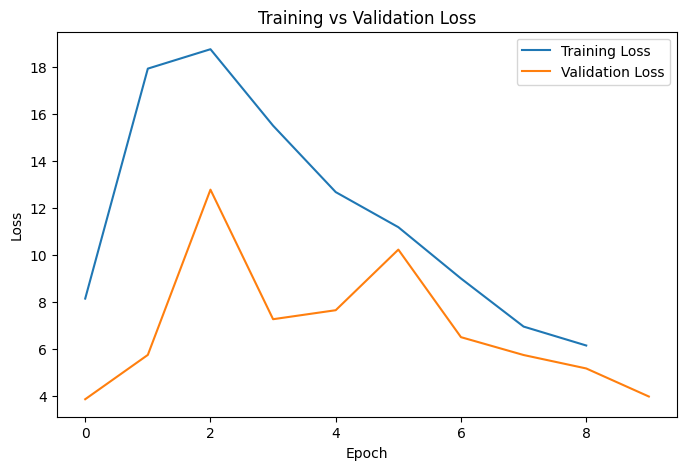

In [37]:
plot_train_loss(history=history)

In [ ]:
# Save the model

model.save('CXC102.keras')
print("Model saved successfully!")

Model saved successfully!


## Load saved model 
loading saved keras model to perform various evaluations 

In [58]:
model = tf.keras.models.load_model('CXC102.keras')

### CNN model summary

In [65]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 382, 382, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 191, 191, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 189, 189, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 94, 94, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 92, 92, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 46, 46, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 270848)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │    34,668,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,287,310 (397.82 MB)

 Trainable params: 34,762,436 (132.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 69,524,874 (265.22 MB)

### Evaluating model against test and validation dataset 

In [ ]:
# Evaludate against test data

results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.8356 - loss: 2.3749
Test Loss: 2.374927043914795
Test Accuracy: 83.56%


In [ ]:
# evaluated against validation dataset
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.8528 - loss: 3.9888
Test Loss: 3.988830804824829
Test Accuracy: 85.28%


## Test dataset evaluation visualisation

2026-05-11 07:17:40.869796: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


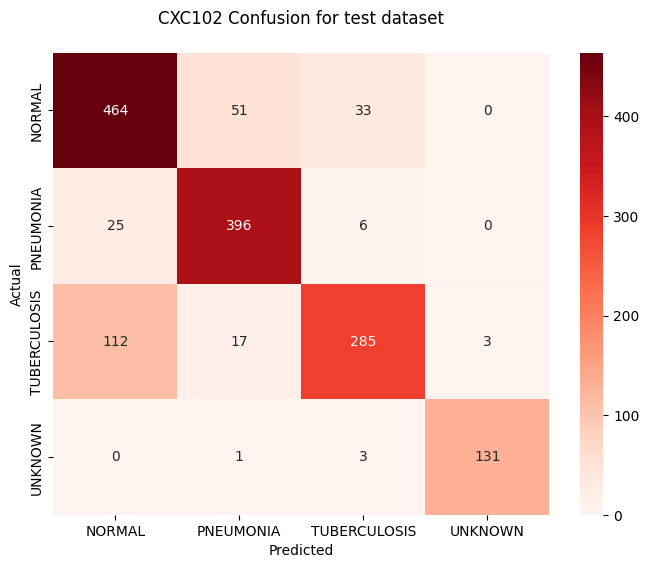

              precision    recall  f1-score   support

      NORMAL       0.77      0.85      0.81       548
   PNEUMONIA       0.85      0.93      0.89       427
TUBERCULOSIS       0.87      0.68      0.77       417
     UNKNOWN       0.98      0.97      0.97       135

    accuracy                           0.84      1527
   macro avg       0.87      0.86      0.86      1527
weighted avg       0.84      0.84      0.83      1527



In [ ]:
# create confusion matrix  and f1 info for test dataset

generate_confusion(
    test_ds, 
    model=model, 
    title="CXC102 Confusion for test dataset"
)

2026-05-11 07:17:45.826869: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


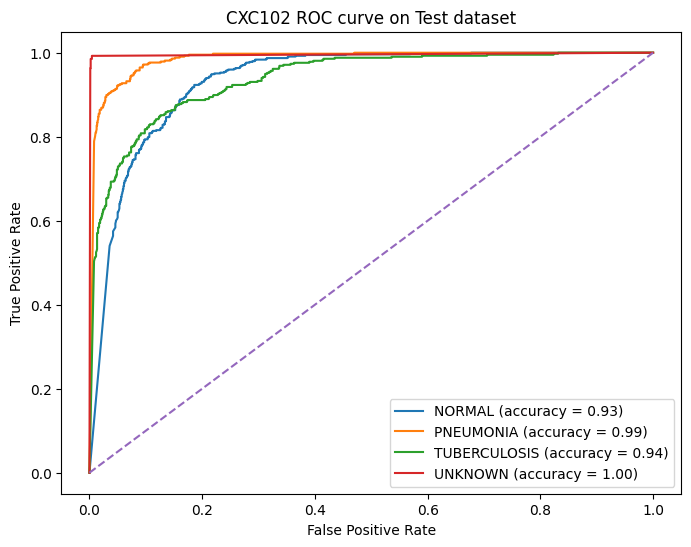

In [62]:
generate_roc_curve(test_ds, model=model, title="CXC102 ROC curve on Test dataset")

## Validate dataset evaluation visualisation

2026-05-11 07:17:48.640223: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


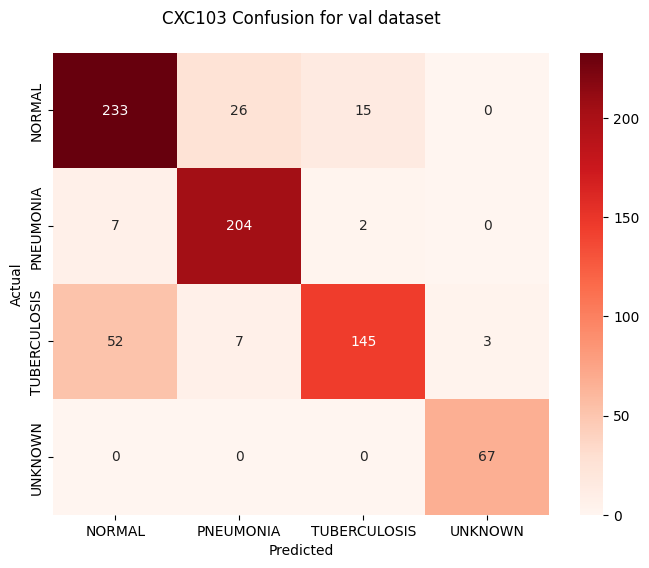

              precision    recall  f1-score   support

      NORMAL       0.80      0.85      0.82       274
   PNEUMONIA       0.86      0.96      0.91       213
TUBERCULOSIS       0.90      0.70      0.79       207
     UNKNOWN       0.96      1.00      0.98        67

    accuracy                           0.85       761
   macro avg       0.88      0.88      0.87       761
weighted avg       0.86      0.85      0.85       761



In [63]:
generate_confusion(val_ds, model=model, title="CXC103 Confusion for val dataset")

2026-05-11 07:17:51.107065: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


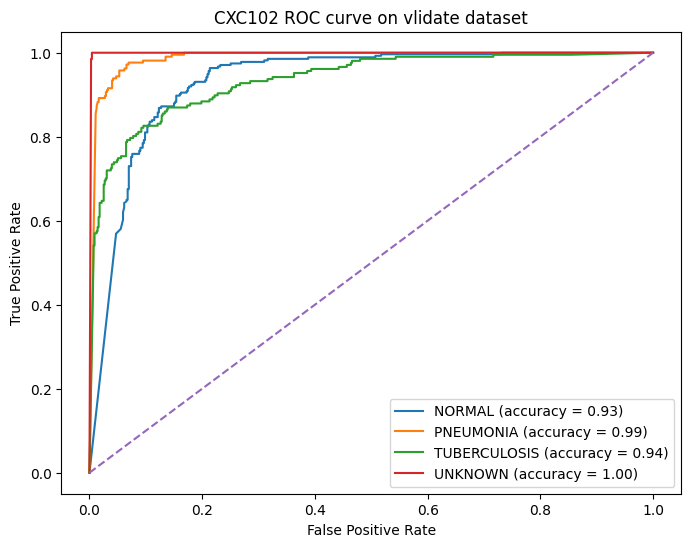

In [64]:
generate_roc_curve(val_ds, model=model, title="CXC102 ROC curve on vlidate dataset")